# Reto Text-based Personality Computing: predicindo Big-5 a partir de Reddit
### **Equipo:** `VAIA` - **Integrantes:** Lucas Amado Oseira, María Lestón Geada e Iria Varela Palmás

**Obxectivo**: predicir, para cada usuario/a de test, as 5 dimensións Big Five (0–100) a partir das súas publicacións en Reddit.

**Métrica**: RMSE medio das 5 dimensións.

Estrutura do notebook:
1. Configuración e carga de datos
2. Limpeza básica e exploración
3. Preparación a nivel de usuario/a
4. Utilidades de validación (K-fold repetido, RMSE medio)
5. Baseline (media do train)
6. Modelo 1: TF-IDF + Ridge
7. Modelo 2: embeddings SBERT + Ridge
8. Ensemble e axuste de redución cara á media
9. Xeración dos CSV de envío
10. Resultados e discusión

Importamos as librerías necesarias para a práctica, que se realizará en Google Colab para garantizar velocidade na obtención dos resultados. Tamén definimos varias constantes: a ruta ao zip que contén os CSVs que empregaremos, a ruta ao directorio no que se descomprimirá dito zip, o nome do equipo e as 5 características a predicir. Ademáis, fixaremos unha semente que nos garantice a reproducibilidade dos resultados.

In [1]:
import re, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import KFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
import zipfile, os
from google.colab import drive

# Montamos Google Drive para acceder aos arquivos
drive.mount('/content/drive')

# Definimos constantes
ZIP_PATH = "/content/drive/MyDrive/material.zip"
DATA = "/content/material"
TEAM = "VAIA"
TRAITS = ["agreeableness","openness","conscientiousness","extraversion","neuroticism"]
SEED = 2710

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Configuración e carga de datos

Comezamos descomprimindo o zip e cargando os tres CSVs.

In [2]:
# Descomprimimos o zip desde Drive e lemos os CSVs
os.makedirs(DATA, exist_ok=True)
with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall(DATA)

# Listamos os arquivos descomprimidos
print(os.listdir(DATA))

# Lemos os CSVs
posts = pd.read_csv(f"{DATA}/posts_v2.csv")   # Posts
tr = pd.read_csv(f"{DATA}/authors_train.csv") # Datos de adestramento
te = pd.read_csv(f"{DATA}/authors_test.csv")  # Datos de test

# Mostramos información básica dos tres dataframes
print("\nposts, train, test:", posts.shape, tr.shape, te.shape)
print("posts columns:", posts.columns.tolist())
print("train columns:", tr.columns.tolist())
print("test columns:", te.columns.tolist())
posts.head()

['authors_test.csv', 'posts_v2.csv', 'authors_train.csv']

posts, train, test: (3125358, 2) (1288, 6) (323, 6)
posts columns: ['username', 'body']
train columns: ['username', 'agreeableness', 'openness', 'conscientiousness', 'extraversion', 'neuroticism']
test columns: ['username', 'agreeableness', 'openness', 'conscientiousness', 'extraversion', 'neuroticism']


,username,body
0,-Areopagan-,Your first and second question is the same que...
1,-Areopagan-,"I have two friends. I alienate everyone, event..."
2,-Areopagan-,I suggest the future. You aren't going back in...
3,-Areopagan-,Yeah I wouldnt want to deal with someone like ...
4,-BigSexy-,I've been asked to cum everywhere with my ex j...


## 2. Limpeza básica e exploración

A continuación, realizamos unha pequena limpeza preliminar do dataset.

As columnas principais dos posts son duas: `username`, que identifica o/a autor/a e tamén está presente nos outros duos arquivos contidos en *tr* e *te*, e `body`, que contén o texto da publicación.

Procedemos a contar o número de nulos por columna.

In [3]:
# Contamos número de nulos por columna
print("Nulos en posts:"); print(posts.isnull().sum())
print("\nNulos nos datos de adestramento:"); print(tr.isnull().sum())
print("\nNulos nos datos de test:"); print(te.isnull().sum())

Nulos en posts:
username     0
body        20
dtype: int64

Nulos nos datos de adestramento:
username              0
agreeableness         4
openness             18
conscientiousness     4
extraversion          3
neuroticism           7
dtype: int64

Nulos nos datos de test:
username               0
agreeableness        323
openness             323
conscientiousness    323
extraversion         323
neuroticism          323
dtype: int64


Vemos que non existen nulos na colunma `username`, o que nos indica que todos os posts teñen un/unha autor/a asociado/a, e que tanto nos posts coma nos datos de adestramento os nulos presentes son mínimos. O que faremos para desfacernos deles será eliminar as publicacións sen texto de *posts*.

Nos datos de test, as 5 columnas están baleiras, pois son os valores a predicir.

En train (*tr*), non imputaremos as etiquetas que faltan. Imputar a media crearía un pico artificial e faría que avaliásemos contra valores inventados. En vez diso, cada trazo adestrarase e avaliarase só cos/as usuarios/as que teñan valor real nese trazo. Por iso, conservaremos algúns *NaN*.

In [ ]:
# Definimos as columnas de usuario e texto de posts
USER_COL = "username"
TEXT_COL = "body"

# Borramos filas con body nulo e convertimos a string
posts = posts.dropna(subset=[TEXT_COL]).copy()
posts[TEXT_COL] = posts[TEXT_COL].astype(str)

# Comprobamos que as columnas restantes existan
assert USER_COL in posts.columns and TEXT_COL in posts.columns, "Axusta USER_COL / TEXT_COL"

# NON TOCAR AINDA
# Eliminamos os nulos de tr para cada trait
# for trait in TRAITS:
#     tr_trait = tr.dropna(subset=[trait])

Posts tras eliminar nulos: 3125338


A continuación, vemos a distribución das puntuacións de personalidade dos datos de adestramento, tanto nunha táboa descriptiva como en histogramas de forma máis visual. Tamén observamos as correlacións entre trazos e a distribución do número e lonxitude das publicacións.

       agreeableness  openness  conscientiousness  extraversion  neuroticism
count         1284.0    1270.0             1284.0        1285.0       1281.0
mean            42.8      62.6               39.5          37.3         49.7
std             31.2      27.8               30.0          30.6         32.3
min              0.0       0.0                0.0           0.0          0.0
25%             14.0      44.0               13.0          10.0         19.0
50%             40.0      69.0               35.0          30.0         49.0
75%             70.0      86.8               63.0          62.0         82.0
max            100.0      99.0               99.0          99.0         99.0


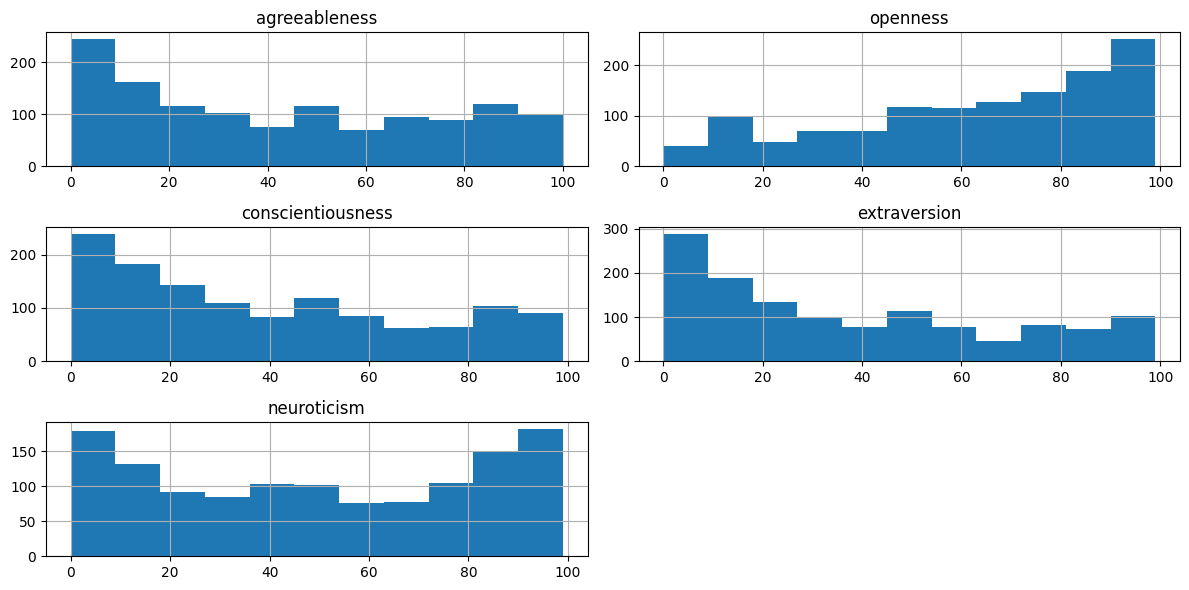

Correlacións entre trazos:
                   agreeableness  openness  conscientiousness  extraversion  \
agreeableness               1.00      0.12               0.05          0.04   
openness                    0.12      1.00              -0.05          0.22   
conscientiousness           0.05     -0.05               1.00          0.04   
extraversion                0.04      0.22               0.04          1.00   
neuroticism                 0.05     -0.00              -0.26         -0.25   

                   neuroticism  
agreeableness             0.05  
openness                 -0.00  
conscientiousness        -0.26  
extraversion             -0.25  
neuroticism               1.00  

Publicacións por usuario/a: count     1572.0
mean      1988.1
std       4554.7
min          1.0
25%         85.0
50%        432.0
75%       1865.5
max      66350.0
dtype: float64

Lonxitude media das publicacións: 37.8 palabras


In [5]:
print(tr[TRAITS].describe().round(1))
tr[TRAITS].hist(bins=11, figsize=(12,6))
plt.tight_layout()
plt.show()

# Correlacións entre traits
print("Correlacións entre trazos:"); print(tr[TRAITS].corr().round(2))

# Exploración de datos de posts
n = posts.groupby(USER_COL).size()
print("\nPublicacións por usuario/a:", n.describe().round(1))
print("\nLonxitude media das publicacións:", posts[TEXT_COL].astype(str).str.split().str.len().mean().round(1), "palabras")

## 3. Agregación a nivel de usuario/a

Sabemos que cada exemplo de adestramento é un/unha usuario/a, polo que debemos reducir os millóns de publicacións a un texto ou vector por persoa.

Para iso, realizaremos un **mostreo aleatorio** de ata `MAX_POSTS` publicacións por usuario/a. Poderíamos quedarnos só coas primeiras ou concatenar todo e cortar, pero decidimos non facelo para non descartar case todo o texto dos usuarios máis activos, ademáis de que non resultaría representativo.

Realizaremos tamén unha nova **limpeza**, que sustituirá todas as *URLS* por `URL` e normalizará os espazos. Finalmente, **concatenaremos** as publicacións de cada usuario/a, establecendo un máximo de `MAX_CHARS` para limitar o custo computacional.

In [ ]:
MAX_POSTS   = 300 # max publicacións por usuario para o TF-IDF, son aleatorias
MAX_CHARS = 20000 # max chars do texto concatenado por usuario

# Función para limpar texto: eliminamos URLs e reducimos espazos
def clean(t):
    t = re.sub(r"http\S+", " URL ", str(t))
    return re.sub(r"\s+", " ", t).strip()

# Realizamos un mostreo aleatorio de publicacións barallando e limitando a MAX_POSTS por usuario
sample = (posts.sample(frac=1, random_state=SEED).groupby(USER_COL).head(MAX_POSTS).copy())
sample["_t"] = sample[TEXT_COL].map(clean) # limpamos só a mostra
sample = sample[sample["_t"].str.len() > 0] # eliminamos publicacións baleiras tras limpar

# Concatenamos as publicacións por usuario e limitamos a MAX_CHARS
user_text = sample.groupby(USER_COL)["_t"].apply(lambda s: " ".join(s)[:MAX_CHARS])

train = tr.merge(user_text.rename("text"), left_on=USER_COL, right_index=True, how="left")
test  = te.merge(user_text.rename("text"), left_on=USER_COL, right_index=True, how="left")

# Contamos os usuarios sen texto en train e test antes de sustituir os nulos
print(train["text"].isna().sum(), "posts en train sen texto e", test["text"].isna().sum(), "posts en test sen texto")
train["text"] = train["text"].fillna("")
test["text"] = test["text"].fillna("")

# Comprobamos que non quedan nulos
print(f"Usuarios sin texto -> Train: {train['text'].isna().sum()} | Test: {test['text'].isna().sum()}")

# Separamos os textos e etiquetas de adestramento
texts = train["text"].values
test_texts = test["text"].values

Y = train[TRAITS].values.astype(float)

29 posts en train sen texto e 10 posts en test sen texto
Usuarios sin texto -> Train: 0 | Test: 0


## 4. Utilidades de validación (K-fold, RMSE medio)

Para comparar os modelos empregamos a validación cruzada K-fold (k=5), que se repetirá `N_REPEATS` veces con particións distintas para reducir o ruído que provocan as pequenas diferenzas azarosas de RMSE.

Debemos ter en conta que o RMSE se vai calcular só sobre as etiquetas reais, ignorando os nulos. 

In [8]:
# RMSE de cada trazo ignorando nulos
def rmse_by_trait(y, p):
    return np.sqrt(np.nanmean((y-p)**2, axis=0))

# RMSE medio ignorando nulos
def rmse_mean(y, p):
    return rmse_by_trait(y, p).mean()

# Convertimos cada array de predición a diccionario con traits
def as_dict(arr):
    return {t: round(float(v), 2) for t, v in zip(TRAITS, arr)}

Realizaremos un adestramento e predicción con Regresión Ridge Multisaída, onde cada trazo se adestra só coas filas que presentan etiqueta nese trazo. As predicións recórtanse a [0, 100], que é o rango válido.

In [9]:
def ridge_multi(A, Ytr, B, alpha):
    p = np.zeros((B.shape[0], len(TRAITS))) # un Ridge por trazo empregando só as filas con etiqueta
    for i in range(len(TRAITS)):
        a = alpha[i] if np.dim(alpha) else alpha # alpha pode ser un escalar ou un valor por trazo
        ok = ~np.isnan(Ytr[:, i]) # filas con etiqueta para o trazo i
        p[:, i] = Ridge(alpha=a, random_state=SEED).fit(A[ok], Ytr[ok, i]).predict(B) # predición para o trazo i
    return np.clip(p, 0, 100) # limitamos predicións entre 0 e 100

Finalmente, gardamos as predicións *out-of-fold (oof)* de cada modelo, que permiten combinar modelos e analizar erros sen volver adestrar. `cv_grid` proba varios valores de `alpha` do Ridge e escolle o mellor por trazo. Como a escolla e a avaliación usan os mesmos datos, o RMSE resultante é lixeiramente optimista, pero o efecto é pequeno, pois só se axusta un hiperparámetro por trazo.

In [10]:
N_REPEATS = 2 # repeticións do K-fold

# Realizamos CV e devolvemos o RMSE medio, un diccionario de RMSE por trazo e a primeira predición OOF
def cv_eval(fit_predict, X, Y, k=5, repeats=N_REPEATS):
    scores, pers, first_oof = [], [], None
    for r in range(repeats):
        oof = np.zeros_like(Y, dtype=float)
        for tri, vai in KFold(k, shuffle=True, random_state=SEED + r).split(X):
            oof[vai] = fit_predict(X[tri], Y[tri], X[vai])
        scores.append(rmse_mean(Y, oof))
        pers.append(rmse_by_trait(Y, oof))
        if first_oof is None:
            first_oof = oof
    return np.mean(scores), as_dict(np.mean(pers, axis=0)), first_oof


# K-fold repetido probando varios alphas e devolvendo a táboa de resultados, mellor alpha por trazo, RMSE medio, diccionario de RMSE por trazo e predicións OOF
# featurize(tri, vai) -> (A_train, A_val) para que o TF-IDF se axuste dentro de cada fold
def cv_grid(featurize, alphas, k=5, repeats=N_REPEATS):
    per = {a: [] for a in alphas}; first = None
    for r in range(repeats):
        oofs = {a: np.zeros_like(Y) for a in alphas}
        for tri, vai in KFold(k, shuffle=True, random_state=SEED + r).split(Y):
            A, B = featurize(tri, vai)
            for a in alphas:
                oofs[a][vai] = ridge_multi(A, Y[tri], B, a)
        for a in alphas: per[a].append(rmse_by_trait(Y, oofs[a]))
        if first is None: first = oofs
    per = {a: np.mean(per[a], axis=0) for a in alphas}
    table = pd.DataFrame(per, index=TRAITS).T # filas = alpha, columnas = trazos
    table["media"] = table.mean(axis=1)
    best = [alphas[int(np.argmin([per[a][j] for a in alphas]))] for j in range(len(TRAITS))] # mellor alpha por trazo
    oof = np.column_stack([first[best[j]][:, j] for j in range(len(TRAITS))])
    score = np.mean([per[best[j]][j] for j in range(len(TRAITS))])
    return table, best, score, as_dict([per[best[j]][j] for j in range(len(TRAITS))]), oof

RESULTS, OOF = {}, {}   # RMSE medio por trazo e predicións oof de cada modelo

## 5. Baseline: predicir a media do train

A Referencia mínima é predicir para todos/as os/as usuarios/as a media de cada trazo, calculada só co train de cada fold. Calquera modelo útil debe superala.

In [11]:
# Modelo base: predición constante co valor medio de cada trazo ignorando nulos
base = lambda Xtr, Ytr, Xva: np.tile(np.nanmean(Ytr, axis=0), (len(Xva),1))
s_base, d_base, o = cv_eval(base, texts, Y)

# Gardamos os resultados do modelo base
RESULTS["baseline"], OOF["baseline"] = (s_base, d_base), o

# Imprimimos o RMSE medio e o diccionario de RMSE por trazo do modelo base
print("Baseline RMSE:", round(s_base, 3), d_base)

Baseline RMSE: 30.398 {'agreeableness': 31.23, 'openness': 27.79, 'conscientiousness': 30.04, 'extraversion': 30.63, 'neuroticism': 32.3}


## 6. Modelo 1: TF-IDF + Ridge
Vectorización clásica con n-gramas e regresión lineal regularizada (multi-saída).

In [12]:
def tfidf_ridge(alpha=3.0):
    def f(Xtr,Ytr,Xva):
        m = make_pipeline(TfidfVectorizer(sublinear_tf=True, min_df=2, max_df=0.9, ngram_range=(1,2), max_features=200000),
                          Ridge(alpha=alpha))
        m.fit(Xtr, Ytr); return np.clip(m.predict(Xva), 0, 100)
    return f
for a in [1, 3, 10, 30]:
    s, d, _ = cv_eval(tfidf_ridge(a), texts, Y)
    print(f"alpha={a:>3}  RMSE={s:.3f}  {d}")

alpha=  1  RMSE=29.688  {'agreeableness': np.float64(30.58), 'openness': np.float64(27.09), 'conscientiousness': np.float64(29.62), 'extraversion': np.float64(29.64), 'neuroticism': np.float64(31.52)}
alpha=  3  RMSE=29.891  {'agreeableness': np.float64(30.78), 'openness': np.float64(27.24), 'conscientiousness': np.float64(29.72), 'extraversion': np.float64(29.99), 'neuroticism': np.float64(31.72)}
alpha= 10  RMSE=30.116  {'agreeableness': np.float64(30.99), 'openness': np.float64(27.42), 'conscientiousness': np.float64(29.86), 'extraversion': np.float64(30.33), 'neuroticism': np.float64(31.97)}
alpha= 30  RMSE=30.232  {'agreeableness': np.float64(31.1), 'openness': np.float64(27.53), 'conscientiousness': np.float64(29.94), 'extraversion': np.float64(30.49), 'neuroticism': np.float64(32.11)}


## 7. Modelo 2: embeddings SBERT + Ridge
Codificamos fragmentos de texto con Sentence-BERT e facemos a media por usuario/a. Require `pip install sentence-transformers` (mellor con GPU/Colab).

In [13]:
!pip install sentence-transformers

In [14]:
from sentence_transformers import SentenceTransformer
sbert = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
def embed_user(u_posts, max_posts=200):
    return sbert.encode(u_posts[:max_posts], batch_size=64, normalize_embeddings=True).mean(axis=0)
users = pd.concat([train[USER_COL], test[USER_COL]]).unique()
g = posts.groupby(USER_COL)[TEXT_COL].apply(lambda s: [clean(x) for x in s])
E = {u: embed_user(g[u]) for u in users if u in g.index}
np.save("emb_sbert.npy", E, allow_pickle=True)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (4 outputs left out)

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

In [15]:
# Ridge sobre embeddings (descomentar cando E estea calculado)
Etr = np.vstack([E.get(u, np.zeros(384)) for u in train[USER_COL]])
for a in [1, 10, 100]:
    f = lambda Xtr,Ytr,Xva: np.clip(Ridge(alpha=a).fit(Xtr,Ytr).predict(Xva),0,100)
    s,d,_ = cv_eval(f, Etr, Y); print(a, round(s,3), d)

1 29.746 {'agreeableness': np.float64(30.68), 'openness': np.float64(27.36), 'conscientiousness': np.float64(29.72), 'extraversion': np.float64(29.52), 'neuroticism': np.float64(31.46)}
10 30.088 {'agreeableness': np.float64(30.91), 'openness': np.float64(27.45), 'conscientiousness': np.float64(29.89), 'extraversion': np.float64(30.28), 'neuroticism': np.float64(31.9)}
100 30.275 {'agreeableness': np.float64(31.13), 'openness': np.float64(27.57), 'conscientiousness': np.float64(29.97), 'extraversion': np.float64(30.54), 'neuroticism': np.float64(32.16)}


## 8. Xeración dos CSV de envío
Formato: `team_name, variant_name, username, agreeableness, openness, conscientiousness, extraversion, neuroticism`; ficheiro `nome_equipo_nome_variante.csv`.

In [16]:
def make_submission(variant, preds):
    df = pd.DataFrame(np.clip(preds,0,100), columns=TRAITS)
    df.insert(0, "username", test[USER_COL].values)
    df.insert(0, "variant_name", variant); df.insert(0, "team_name", TEAM)
    assert len(df)==len(te) and df[TRAITS].notna().all().all()
    fn = f"{TEAM}_{variant}.csv"; df.to_csv(fn, index=False); print("Gardado", fn)
    return df

make_submission("baseline", base(texts, Y, test["text"].values))
make_submission("tfidf_ridge", tfidf_ridge(10)(texts, Y, test["text"].values))

Gardado VAIA_baseline.csv
Gardado VAIA_tfidf_ridge.csv


,team_name,variant_name,username,agreeableness,openness,conscientiousness,extraversion,neuroticism
0,VAIA,tfidf_ridge,libelle156,43.966857,62.523423,39.531692,35.941011,51.264190
1,VAIA,tfidf_ridge,drawtheApocalypse,42.491762,60.163780,40.142655,35.351901,47.629741
2,VAIA,tfidf_ridge,I_hate_kittens_,41.527535,63.889424,38.904250,36.617862,46.615730
3,VAIA,tfidf_ridge,gillybean103,43.706442,62.366440,40.901701,37.417191,50.602721
4,VAIA,tfidf_ridge,DivinePetal,41.280596,61.143253,38.808475,37.160530,49.718382
...,...,...,...,...,...,...,...,...
318,VAIA,tfidf_ridge,RetardYourAnger,43.065354,63.552946,38.184982,36.702272,49.314106
319,VAIA,tfidf_ridge,cultcrime,42.590328,63.167210,38.269074,38.799318,50.061782
320,VAIA,tfidf_ridge,y_mr_y,42.908910,62.129799,39.402927,38.892729,50.374631
321,VAIA,tfidf_ridge,nman10000,41.650854,61.592820,39.892031,35.717135,50.300955


## 9. Resultados e discusión
_(Encher: táboa comparativa de RMSE por modelo e trazo, análise de erros, que funcionou e que non, ideas futuras: filtrado de publicacións por trazo, cuestionarios con SBERT, fine-tuning, LLMs few-shot.)_